In [1]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [2]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
# from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches
from f2_utils import *
import time_in_each_roi
import matplotlib

In [3]:

mouse='cm265'
step_0_root = str(STEPS / "step_0") + "/"
step_1_root = str(STEPS / "step_1") + "/"
step_2_root = str(STEPS / "step_2") + "/"
step_3_root = str(STEPS / "step_3") + "/"

fetch_path_sensory = str(PREPARES / "index-S1") + "/"
fetch_path_motor = str(PREPARES / "index-M2") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
fetch_path_M1 = str(PREPARES / "index-extra") + "/"

h5_root = step_3_root+mouse+'/dlc_h5s/'
video_root = step_3_root+mouse+'/dlc_side_movies/'
mirror_h5_root = step_3_root+mouse+'/dlc_mirror_h5s/'
load_path = str(PREPARES / "epochs-csn") + "/"

figure_config_root = str(PREPARES / "config") + "/"


In [4]:
M2_ind = load_pickle(fetch_path_motor+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_sensory+'brightest_ind_'+mouse)
# sensory_ind.pop('nose')


In [5]:
def show_map(data,caxis,if_return_map=False,cmap='rocket'):
    ss_idx = IDX_sorted.shape;
    IDX_reshape = IDX_sorted.reshape((-1,1))
    tmp = np.empty((ss_idx[0]*ss_idx[1],1))
    tmp[:] = np.nan
    std_map = tmp
    ncomps=500
    for i_region in range(ncomps):
        indice = IDX_reshape == i_region+1
        std_map[indice] =  data[i_region]
    # reshape back
    std_map = np.reshape(std_map,(ss_idx[0],ss_idx[1]))
    plt.imshow(std_map,vmin=caxis[0],vmax=caxis[1],cmap=cmap)
    plt.axis('off')
    plt.colorbar(fraction=0.046, pad=0.04)
    if if_return_map ==True:
        return std_map
    
    
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_63094/2796072416.py:7: RuntimeWarning: invalid value encountered in cast
  props = regionprops(IDX_sorted.astype(int))


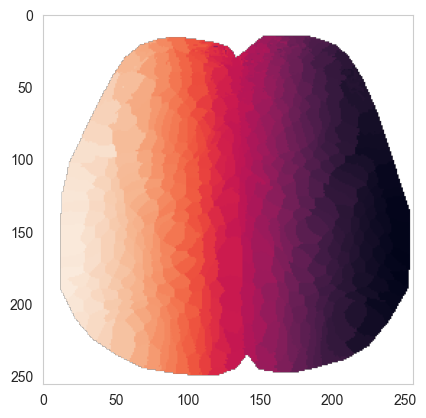

In [6]:
with h5py.File(step_0_root+mouse+'/idx_sorted_500_'+mouse+'.mat','r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
plt.imshow(IDX_sorted)


In [7]:
all_gathered = ['rotf_norm','rotf_smooth_norm','LFP_vel_norm',
           'RFP_vel_norm','RFP_side_vel_norm',
     'RHP_side_vel_norm','tail_side_vel_norm','RFP_side_vel','RHP_side_vel',
     'tail_side_vel','LFP_vel','RFP_vel','RFP_vel_smooth','is_lick',
          'is_groom','ind_start','ind_stop','day_label','y_rise_RFP','jrgeco','gcamp']


f = scipy.io.loadmat(load_path+'RHP_'+mouse+'_filtered.mat'
                       )

for key in all_gathered:
    exec("M_{} = np.squeeze(f['M_{}'])".format(key,key))


# dlc_joint=load_model(prefix+'users/wx2203/new_analysis_locker/pub-locker/acadia-M1/'+'RHP_'+mouse+'_raw_data_joint')


for i,label in enumerate(M_day_label):
    M_day_label[i]=label.split(' ')[0]

T_PRE=77
T_POST=153
    

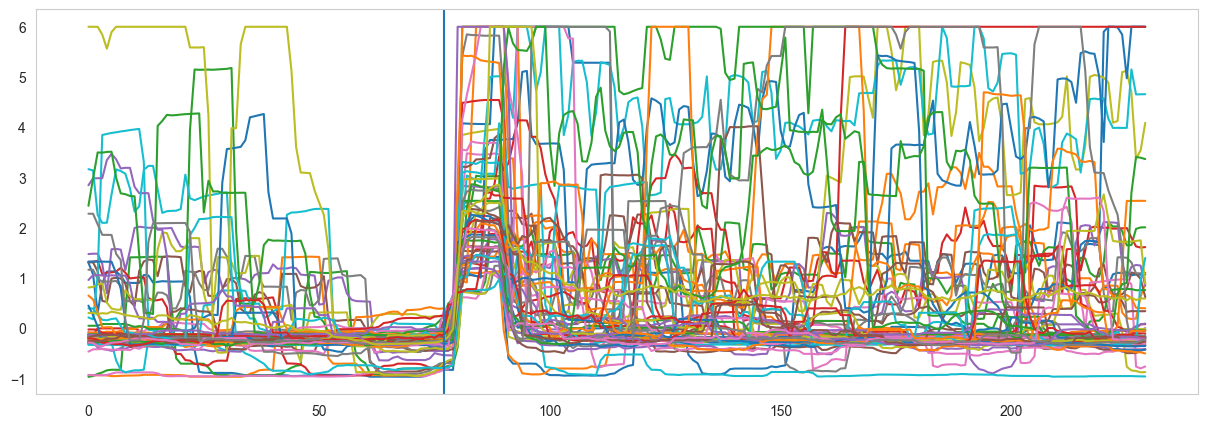

In [8]:
plt.figure(figsize=(15,5))
for i in range(M_RHP_side_vel_norm.shape[-1]):
    plt.plot(M_RHP_side_vel_norm[:,i])
plt.plot(np.mean(M_RHP_side_vel_norm,-1))
plt.axvline(T_PRE)

In [9]:
oo = np.array([1,7,10,11,13,14,15,16,
               17,18,24,25,27,28,35,
               36,37,43,46,47,48,49,50,
               51,52,53,54])-1

# remove bouts with bad imaging quality caused by motion

In [10]:
beh_list_1=['rotf_norm','rotf_smooth_norm','LFP_vel_norm',
           'RFP_vel_norm','RFP_side_vel_norm',
     'RHP_side_vel_norm','tail_side_vel_norm','RFP_side_vel','RHP_side_vel',
     'tail_side_vel','LFP_vel','RFP_vel','RFP_vel_smooth','is_lick',
          'is_groom','y_rise_RFP']
for item in beh_list_1:
    exec("M_{}= M_{}[T_PRE-15:T_PRE+60,oo]".format(item,item))
beh_list_2 = ['ind_start','ind_stop','day_label']
for item in beh_list_2:
    exec("M_{}= M_{}[oo]".format(item,item))
    
M_jrgeco = M_jrgeco[:,T_PRE-15:T_PRE+60,oo]  
M_gcamp = M_gcamp[:,T_PRE-15:T_PRE+60,oo]  

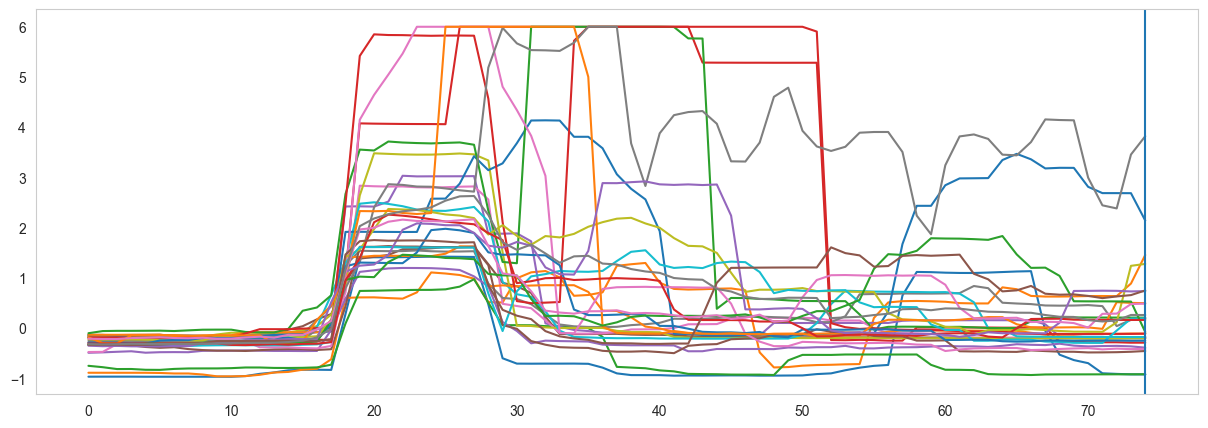

In [11]:
plt.figure(figsize=(15,5))
for i in range(M_RHP_side_vel_norm.shape[-1]):
    plt.plot(M_RHP_side_vel_norm[:,i])
plt.plot(np.mean(M_RHP_side_vel_norm,-1))
plt.axvline(T_PRE-3)

In [12]:
T_PRE=15

In [13]:
save_list=['rotf_norm','rotf_smooth_norm','LFP_vel_norm',
           'RFP_vel_norm','RFP_side_vel_norm',
     'RHP_side_vel_norm','tail_side_vel_norm','RFP_side_vel','RHP_side_vel',
     'tail_side_vel','LFP_vel','RFP_vel','RFP_vel_smooth','is_lick',
          'is_groom','ind_start','ind_stop','day_label','y_rise_RFP','jrgeco','gcamp',
           ]

save_dict = {}
for item in save_list:
    exec("save_dict['M_{}']= M_{}".format(item,item))
    


**save final**

In [14]:
# save_dict['T_PRE'] = T_PRE
# scipy.io.savemat(load_path+'RHP_'+mouse+'_final.mat',
#                        save_dict)



In [15]:
all_gathered = ['rotf_norm','rotf_smooth_norm','LFP_vel_norm',
           'RFP_vel_norm','RFP_side_vel_norm',
     'RHP_side_vel_norm','tail_side_vel_norm','RFP_side_vel','RHP_side_vel',
     'tail_side_vel','LFP_vel','RFP_vel','RFP_vel_smooth','is_lick',
          'is_groom','ind_start','ind_stop','day_label','y_rise_RFP','jrgeco','gcamp']

f = scipy.io.loadmat(load_path+'RHP_'+mouse+'_final.mat'
                       )

for key in all_gathered:
    exec("M_{} = np.squeeze(f['M_{}'])".format(key,key))
    
T_PRE = 15

In [16]:
norm_M_gcamp = M_gcamp - np.mean(M_gcamp[:,T_PRE-15:T_PRE-5,:],axis=1)[:,np.newaxis,:]
norm_M_jrgeco = M_jrgeco - np.mean(M_jrgeco[:,T_PRE-15:T_PRE-5,:],axis=1)[:,np.newaxis,:]
norm_M_RFP_vel_norm = M_RFP_vel_norm - np.mean(M_RFP_vel_norm[T_PRE-15:T_PRE-5,:],axis=0)[np.newaxis,:]
norm_M_RHP_side_vel_norm = M_RHP_side_vel_norm - np.mean(M_RHP_side_vel_norm[T_PRE-15:T_PRE-5,:],axis=0)[np.newaxis,:]



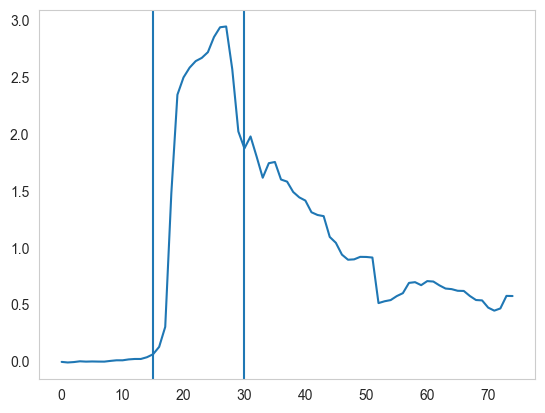

In [17]:
plt.plot(np.mean(norm_M_RHP_side_vel_norm,-1))
plt.axvline(15)
plt.axvline(30)

Text(91.36206817626953, 152.24713134765625, '*')

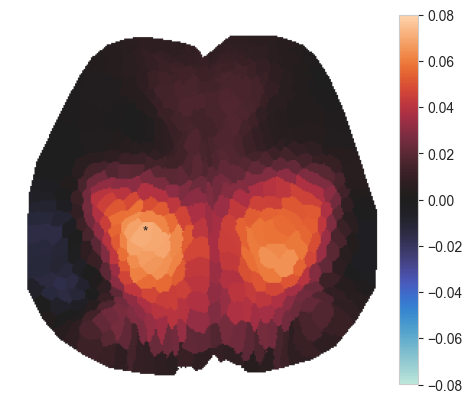

In [18]:
snap = np.mean(np.mean(norm_M_jrgeco[:,T_PRE:T_PRE+15,:],-1),-1)
show_map(snap,caxis=[-0.08,0.08],cmap='icefire',if_return_map=False)
plt.text(node_coords[sensory_ind['RHP'],1],node_coords[sensory_ind['RHP'],0],'*')

Text(91.36206817626953, 152.24713134765625, '*')

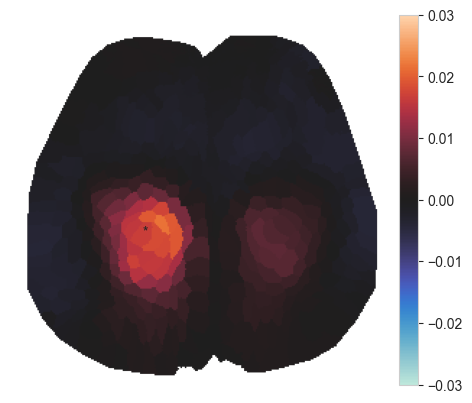

In [19]:
snap = np.mean(np.mean(norm_M_gcamp[:,T_PRE:T_PRE+15,:],-1),-1)
show_map(snap,caxis=[-0.03,0.03],cmap='icefire',if_return_map=False)
plt.text(node_coords[sensory_ind['RHP'],1],node_coords[sensory_ind['RHP'],0],'*')

In [20]:
M_ind_start.shape

(27,)

In [22]:
# MM_jrgeco = np.empty((256,256,75,0))
# MM_gcamp = np.empty((256,256,75,0))
# for i_bout in range(norm_M_jrgeco.shape[-1]): 
#     session_id = M_day_label[i_bout]
#     day = session_id.split(mouse+'_')[1].split('_')[0]
#     run_id = session_id.split(mouse+'_')[1].split('_')[1]
#     run_id = run_id.split(' ')[0]
#     f3 = list(set(glob.glob(step_1_root+mouse+"/"+day+"/*"+run_id+"*.mat")))[0]
#     ind = int(M_ind_start[i_bout]-3) # new T_PRE 3 frames ahead (cm265)

#     with h5py.File(f3,'r') as f_H: 
#         m = f_H['m']
#         C = np.array(f_H['C']['jrgeco'])
#         S = np.array(f_H['S']['jrgeco'])[ind-15:ind+60,:]
#         # cut [-60,60] frames slice
#         mask = np.array(f_H['mask'])
#         # nanidx = np.squeeze(~np.isnan(mask.reshape((1,-1))))
#         nanidx = np.squeeze(m['nanidx'])==1
#         CS = np.dot(S,C).transpose()
#         jrgeco = np.zeros((len(nanidx),CS.shape[-1]))
#         jrgeco[:] = np.nan
#         jrgeco[nanidx==True,:] = CS
#         jrgeco = jrgeco.reshape((256,256,-1)).transpose((1,0,2))

#         C = np.array(f_H['C']['gcamp'])
#         S = np.array(f_H['S']['gcamp'])[ind-15:ind+60,:]
#         # cut [-60,60] frames slice
#         CS = np.dot(S,C).transpose()
#         gcamp = np.zeros((len(nanidx),CS.shape[-1]))
#         gcamp[:] = np.nan
#         gcamp[nanidx==True,:] = CS
#         gcamp = gcamp.reshape((256,256,-1)).transpose((1,0,2))        
        
#         # de-baseline too
#         # gcamp_norm = gcamp -np.mean(gcamp[:,:,bsl],axis=-1)[:,:,np.newaxis]
#         bsl = range(0,15)
#         for i_fluorofore,fluorophore in enumerate(['jrgeco','gcamp']):
#             exec("{}_norm = {}-np.mean({}[:,:,bsl],axis=-1)[:,:,np.newaxis]".format(fluorophore,fluorophore,fluorophore))
#         MM_jrgeco = np.append(MM_jrgeco,jrgeco_norm[:,:,:,np.newaxis],axis=3)
#         MM_gcamp = np.append(MM_gcamp,gcamp_norm[:,:,:,np.newaxis],axis=3)  
    
#     # print(MM_jrgeco.shape)

 

In [ ]:
# s1m1_save_path = load_path
# hf = h5py.File(s1m1_save_path+'MM_'+mouse, 'w')
# hf.create_dataset('MM_jrgeco', data=MM_jrgeco)
# hf.create_dataset('MM_gcamp', data=MM_gcamp)
# hf.close()

In [23]:
s1m1_save_path = load_path
hf = h5py.File(s1m1_save_path+'MM_'+mouse, 'r')
MM_jrgeco = np.array(hf.get('MM_jrgeco'))
MM_gcamp = np.array(hf.get('MM_gcamp'))
hf.close()


In [24]:
s1m1_save_path

'/Volumes/WX/scratch/prepares_data/epochs-csn/'

In [25]:
AVG_jrgeco = np.mean(MM_jrgeco,-1)
AVG_gcamp = np.mean(MM_gcamp,-1)

In [26]:
M1_ind=334 # CM265

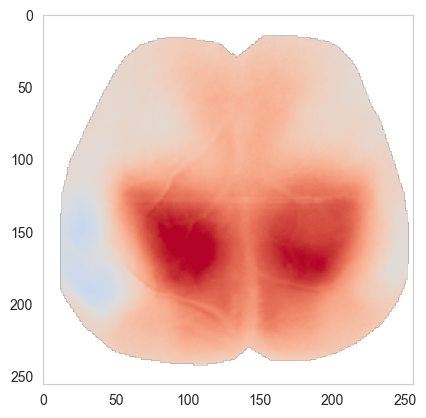

In [27]:
plt.imshow(np.mean(AVG_jrgeco[:,:,15:20],-1),vmin=-0.06,vmax=0.06,cmap='coolwarm')

Text(99.96295928955078, 155.06790161132812, '*')

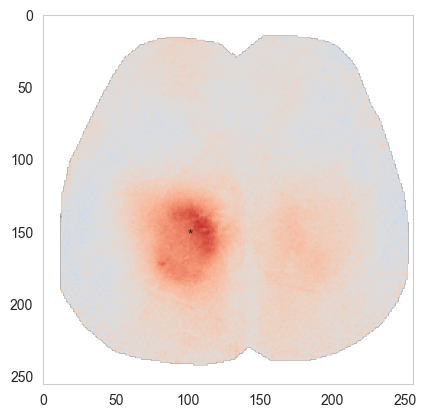

In [28]:
plt.imshow(np.mean(AVG_gcamp[:,:,15:20],-1),vmin=-0.02,vmax=0.02,cmap='coolwarm')
plt.text(node_coords[M1_ind,1],node_coords[M1_ind,0],'*')

# make figure

In [29]:
avg_time_series = np.array([18,24])

In [30]:
seed_ROI_xy = {'S1':[],
              'M1':[]}

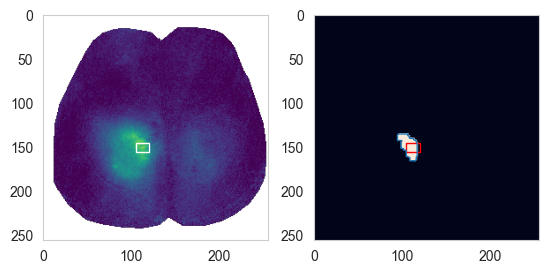

In [31]:
from skimage import measure
avg_clean_contours_series={}

ax1=plt.subplot(121)
plt.imshow(AVG_gcamp[:,:,avg_time_series[0]],vmin=-0.0,vmax=0.03,cmap='viridis')
ax2=plt.subplot(122)
boolean_img = AVG_gcamp[:,:,avg_time_series[0]]>0.017

boolean_img = boolean_img.astype('int')
kernel = np.ones((7,7),np.uint8)
opening = cv2.morphologyEx(np.uint8(boolean_img), cv2.MORPH_OPEN, kernel)

contours = measure.find_contours(opening, 0.8)
clean_contours=[]
for i_contour,contour in enumerate(contours):
    if len(contour)<30:
        # print('place holder')
        a=1
    else:
        clean_contours.append(contours[i_contour])
            
plt.imshow(opening,vmax=0.02)
for contour in clean_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1)

avg_clean_contours_series[0]={}
avg_clean_contours_series[0]['time_frame'] = avg_time_series[0]
avg_clean_contours_series[0]['clean_contours'] = clean_contours
avg_clean_contours_series[0]['threshold'] = 0.019

from matplotlib import patches
y_top_left=105;y_botton_right=120;x_top_left=145;x_botton_right=155;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax1.add_patch(rect)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='red',facecolor='none')

ax2.add_patch(rect)
seed_ROI_xy['M1']={}
seed_ROI_xy['M1']['y_top_left']=y_top_left
seed_ROI_xy['M1']['y_botton_right']=y_botton_right
seed_ROI_xy['M1']['x_top_left']=x_top_left
seed_ROI_xy['M1']['x_botton_right']=x_botton_right

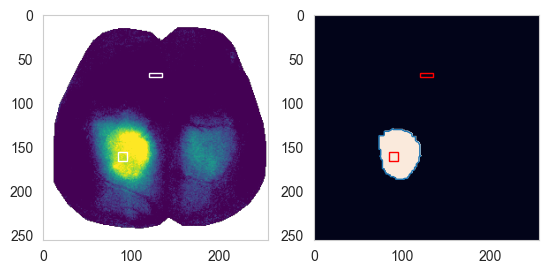

In [32]:
ax1=plt.subplot(121)
plt.imshow(AVG_gcamp[:,:,avg_time_series[1]],vmin=-0.0,vmax=0.02,cmap='viridis')
ax2=plt.subplot(122)
boolean_img = AVG_gcamp[:,:,avg_time_series[1]]>0.015

boolean_img = boolean_img.astype('int')
kernel = np.ones((7,7),np.uint8)
# opening = cv2.morphologyEx(np.uint8(boolean_img), cv2.MORPH_OPEN, kernel)
opening = cv2.dilate(np.uint8(boolean_img), kernel)
# kernel = np.ones((4,4),np.uint8)
opening = cv2.erode(opening,kernel)


plt.imshow(opening,vmax=0.06)

contours = measure.find_contours(opening, 0.8)
clean_contours=[]
for i_contour,contour in enumerate(contours):
    if len(contour)<30:
        # print('place holder')
        a=1
    else:
        clean_contours.append(contours[i_contour])
            
plt.imshow(opening,vmax=0.06)
for contour in clean_contours:
    plt.plot(contour[:,1],contour[:,0],linewidth=1)


avg_clean_contours_series[1]={}
avg_clean_contours_series[1]['time_frame'] = avg_time_series[0]
avg_clean_contours_series[1]['clean_contours'] = clean_contours
avg_clean_contours_series[1]['threshold'] = 0.015


from matplotlib import patches
y_top_left=85;y_botton_right=95;x_top_left=155;x_botton_right=165;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax1.add_patch(rect)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='red',facecolor='none')

ax2.add_patch(rect)
seed_ROI_xy['S1']={}
seed_ROI_xy['S1']['y_top_left']=y_top_left
seed_ROI_xy['S1']['y_botton_right']=y_botton_right
seed_ROI_xy['S1']['x_top_left']=x_top_left
seed_ROI_xy['S1']['x_botton_right']=x_botton_right

y_top_left=120;y_botton_right=135;x_top_left=65;x_botton_right=70;
out_h = int(x_botton_right - x_top_left);out_w = int(y_botton_right - y_top_left) 
y = int(x_top_left);x = int(y_top_left)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='white',facecolor='none')
ax1.add_patch(rect)
rect = patches.Rectangle((x,y),out_w,out_h,linewidth=1,edgecolor='red',facecolor='none')

ax2.add_patch(rect)
seed_ROI_xy['M2']={}
seed_ROI_xy['M2']['y_top_left']=y_top_left
seed_ROI_xy['M2']['y_botton_right']=y_botton_right
seed_ROI_xy['M2']['x_top_left']=x_top_left
seed_ROI_xy['M2']['x_botton_right']=x_botton_right

In [ ]:
ind = int(M_ind_start[0])
f3 = glob.glob(step_1_root+mouse+"/"+'2'+"/*"+'runI'+"*.mat")[0]
with h5py.File(f3,'r') as f_H: 
    m = f_H['m']
    C = np.array(f_H['C']['lime'])
    S = np.array(f_H['S']['lime'])[ind+10:ind+13,:]
    # cut [-60,60] frames slice
    CS = np.dot(S,C).transpose()
    lime = CS
    lime = lime.reshape((256,256,-1)).transpose((1,0,2))        
    mask=np.array(f_H['mask']).transpose()
    
lime = np.multiply(mask,lime[:,:,0])

In [33]:
MM_gcamp.shape

(256, 256, 75, 27)

In [35]:
gcamp2plot = {};jrgeco2plot={};node_coords_S1M1 = {}
for i_area,area in enumerate(['S1','M1','M2']):
    y_top_left = seed_ROI_xy[area]['y_top_left']
    y_botton_right = seed_ROI_xy[area]['y_botton_right']
    x_top_left =seed_ROI_xy[area]['x_top_left']
    x_botton_right=seed_ROI_xy[area]['x_botton_right']
    node_coords_S1M1[area] = np.array([(y_top_left+y_botton_right)/2,(x_top_left+x_botton_right)/2])
    small_roi_tcs = np.nanmean(np.nanmean(
MM_gcamp[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    gcamp2plot[area] = small_roi_tcs
    
    small_roi_tcs = np.nanmean(np.nanmean(
MM_jrgeco[x_top_left:x_botton_right,y_top_left:y_botton_right],0),0)
    jrgeco2plot[area] = small_roi_tcs

In [36]:
palatte_dict = load_pickle(figure_config_root+'palatte_dict')
new_palatte_dict={}
new_palatte_dict['S1']='#015EB5'
new_palatte_dict['M2']='#6DAE96'  
new_palatte_dict['M1']= '#C44B30'     
palatte_dict['RHP_M2']='#6dae96'
palatte_dict['RHP_M1']='#4b0082'
palatte_dict['RHP_S1']=palatte_dict['RHP']
palette1=['#e97877','#0c4666','#adcee9','#f4c784']

In [37]:
t_stop=80

In [ ]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T
    
# mask out midline
mask_midline_array = np.repeat(mask_midline[:,:,np.newaxis],repeats=AVG_gcamp.shape[-1],axis=2)
AVG_gcamp = np.multiply(AVG_gcamp,mask_midline_array)
AVG_jrgeco = np.multiply(AVG_jrgeco,mask_midline_array)

lime = np.multiply(lime,mask_midline)


In [41]:
from matplotlib import cm
icefire = cm.get_cmap('icefire')
viridis = cm.get_cmap('viridis')
fire_cmap = load_pickle(figure_config_root+'fire_cmap')

/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_63094/1880093458.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  icefire = cm.get_cmap('icefire')
/var/folders/kd/ywhkc6v94gq46vrbg78rzh240000gq/T/ipykernel_63094/1880093458.py:3: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis = cm.get_cmap('viridis')


In [42]:
load_path =  str(FIGURES / "figure5") + "/"
homunculus_rois = load_pickle(load_path+'homunculus_rois_unregistered_'+mouse)
clean_contours = load_pickle(load_path+'clean_contours_unregistered_'+mouse)

(-1.0, 1.35)

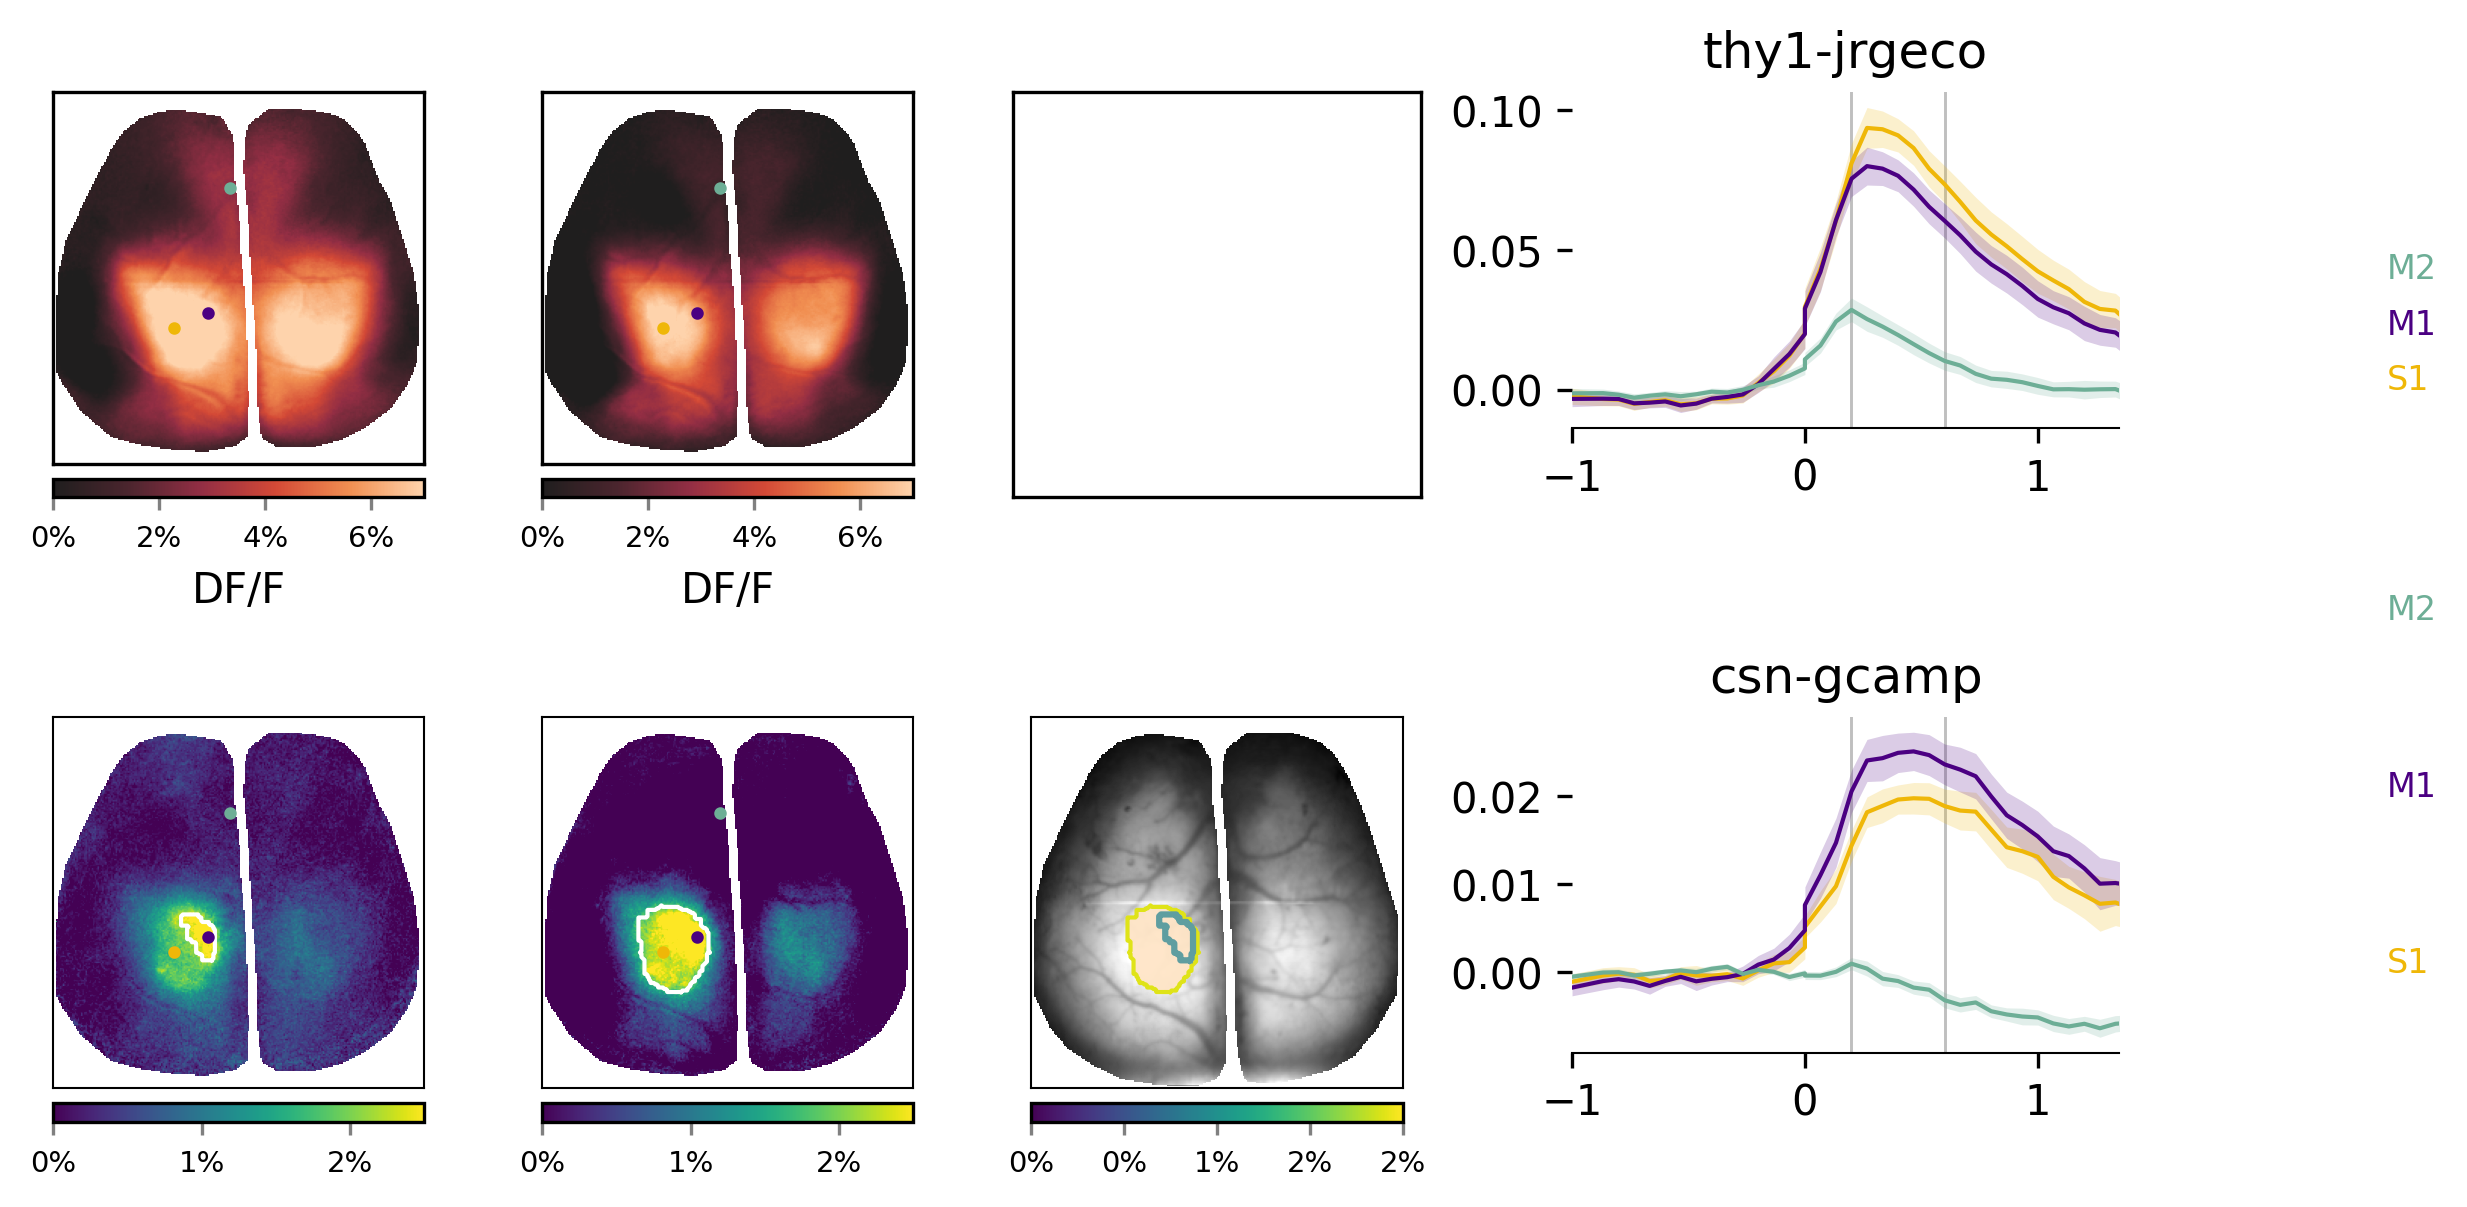

In [ ]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable

plt.style.use('default')
plt.rcParams['svg.fonttype'] = 'none'

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;y_gap=2;x_gap=2;x_width=6;y_gap=2;x_gap_four = 0;

y_start = y_offset 
y_stop = y_start + x_width
x_start = x_offset
x_stop = x_start + x_width
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+1 
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xlim([10,256]);ax{}.set_ylim([250,4])".format(i_ax,i_ax))
    # exec("ax{}.set_xlim([21,256]);ax{}.set_ylim([248,18])".format(i_ax,i_ax))


y_start = y_offset - 9
y_stop = y_start + x_width
x_start = x_offset
x_stop = x_start + x_width
# THY1-JRGECO
for i_ax in range(10,13):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    x_start = x_stop+1 
    x_stop = x_start + x_width
    exec("ax{}.set_xticks([])".format(i_ax))
    exec("ax{}.set_yticks([])".format(i_ax))
    exec("ax{}.set_xlim([10,256]);ax{}.set_ylim([250,4])".format(i_ax,i_ax))
    
    
x_start = x_offset+22
x_stop = x_start + 8
y_start = y_offset - 9
y_stop = y_start +5
for i_ax in range(3,5):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop+4
    y_stop = y_start + 5

# ax5 = fig.add_subplot(gs[y_start:y_stop+1,x_start:x_stop+1])
# ax5.set_aspect('equal', adjustable='box')
    
for i_t,i_ax in enumerate(range(0,2)):
   
    exec("sbp{} = ax{}.imshow(AVG_gcamp[:,:,avg_time_series[i_t]],vmin=0,vmax=0.02,aspect='equal',cmap='viridis')".format(i_ax,i_ax))
    exec("divider = make_axes_locatable(ax{})".format(i_ax))
    cax = divider.append_axes('bottom', size='5%', pad=0.05)
    exec("cb=fig.colorbar(sbp{}, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    from matplotlib import ticker
    tick_locator = ticker.MaxNLocator(nbins=3)
    cb.locator = tick_locator
    cb.update_ticks()
    
# THY1-JRGECO
for i_t,i_ax in enumerate(range(10,12)):
    if i_ax==10:
        exec("sbp{} = ax{}.imshow(AVG_jrgeco[:,:,avg_time_series[i_t]],vmin=0,vmax=0.07,aspect='equal',cmap=fire_cmap)".format(i_ax,i_ax))
    if i_ax==11:
        exec("sbp{} = ax{}.imshow(AVG_jrgeco[:,:,avg_time_series[i_t]],vmin=0,vmax=0.07,aspect='equal',cmap=fire_cmap)".format(i_ax,i_ax))

    exec("divider = make_axes_locatable(ax{})".format(i_ax))
    cax = divider.append_axes('bottom', size='5%', pad=0.05)
    exec("cb=fig.colorbar(sbp{}, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))".format(i_ax))
    cb.ax.tick_params(labelsize=7,length=3,color='gray')
    cb.ax.set_xlabel('DF/F')
    
    
ax2.imshow(lime,cmap='gray',vmin=500,vmax=5000,aspect='equal')
i_ax=2
exec("divider = make_axes_locatable(ax{})".format(i_ax))
cax = divider.append_axes('bottom', size='5%', pad=0.05)
cb=fig.colorbar(sbp0, cax=cax,orientation='horizontal',format=FuncFormatter(fmt))
cb.ax.tick_params(labelsize=7,length=3,color='gray')


t_stop=45
t_start = 15
t_frame = np.linspace(-15,30,45).astype('int')
t_ax = np.divide(t_frame,15)


new_palatte = ['#8F4834', '#306F5A' ,'#EACD41', 'indigo','#171E26','#6DAE96' , '#C44B30']

all_gathered_3 = {'norm_M_RHP_side_vel_norm':'HP(R) speed',
                  'norm_M_RFP_vel_norm':'FP(R) speed'}
    
# for i_beh,beh in enumerate(all_gathered_3):
#     exec("data2plot = {}[:t_stop,:]".format(beh))
#     avg = np.mean(data2plot,axis=-1)
#     sem = stats.sem(data2plot,axis=-1)
     
#     ax3.plot(t_ax,avg+i_beh*0,color=palette1[i_beh],linewidth =1)
#     ax3.fill_between(t_ax,avg+i_beh*0 - sem,avg +i_beh*0+sem,linewidth =0,color=palette1[i_beh],alpha=0.2)
#     exec("ax3.text(t_ax[-1]-t_ax[0]-0.7,0.8*i_beh,all_gathered_3[beh],color=palette1[i_beh],fontsize=8)".format(beh))
    
# for i_key,key in enumerate(new_choice_ind):
#     ind = new_choice_ind[key]
#     data2plot = norm_M_gcamp[ind,:t_stop,:]
#     avg = np.mean(data2plot,axis=-1)
#     sem = stats.sem(data2plot,axis=-1)
#     ax4.plot(t_ax,avg,label=key,color=palatte_dict['RFP_'+key],linewidth =1)
#     ax4.fill_between(t_ax,avg - sem,avg +sem,color=palatte_dict['RFP_'+key],linewidth =0,alpha=0.2)
#     ax4.text(t_ax[-1]-t_ax[0]-0.5,0.02*i_key,key,color=palatte_dict['RFP_'+key],fontsize=8)
    
    
    
for i_key,key in enumerate(['S1','M1','M2']):
    data2plot = jrgeco2plot[key][:t_stop,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax3.plot(t_ax,avg,label=key,color=palatte_dict['RHP_'+key],linewidth =1)
    ax3.fill_between(t_ax,avg - sem,avg +sem,color=palatte_dict['RHP_'+key],linewidth =0,alpha=0.2)
    ax3.text(t_ax[-1]-t_ax[0]-0.5,0.02*i_key,key,color=palatte_dict['RHP_'+key],fontsize=8)
ax3.set_title('thy1-jrgeco')    



for i_key,key in enumerate(['S1','M1','M2']):
    data2plot = gcamp2plot[key][:t_stop,:]
    avg = np.mean(data2plot,axis=-1)
    sem = stats.sem(data2plot,axis=-1)
    ax4.plot(t_ax,avg,label=key,color=palatte_dict['RHP_'+key],linewidth =1)
    ax4.fill_between(t_ax,avg - sem,avg +sem,color=palatte_dict['RHP_'+key],linewidth =0,alpha=0.2)
    ax4.text(t_ax[-1]-t_ax[0]-0.5,0.02*i_key,key,color=palatte_dict['RHP_'+key],fontsize=8)
ax4.set_title('csn-gcamp')  
    
    
# # trajectory plot
# z = range(M1_bouts.shape[0])
# sbp5 = ax5.scatter(np.mean(M1_bouts,-1),np.mean(S1_bouts,-1), c=z, marker='.',s=10,cmap='viridis')
# ax5.plot(np.mean(M1_bouts,-1),np.mean(S1_bouts,-1),c='gray',alpha=0.3)
# ax5.set_xlim([-0.005,0.03])
# ax5.set_ylim([-0.005,0.03])

# i_ax=5
# exec("divider = make_axes_locatable(ax{})".format(i_ax))
# cax = divider.append_axes('right', size='5%', pad=0.05)
# cb=fig.colorbar(sbp5, cax=cax,orientation='vertical')
# cb.ax.tick_params(labelsize=7,length=3,color='gray')
# tick_locator = ticker.MaxNLocator(nbins=2)
# cb.locator = tick_locator
# cb.update_ticks()
            
# plot contours
S1_contours = avg_clean_contours_series[1]['clean_contours']
for contour in S1_contours:
    ax1.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
    ax2.plot(contour[:,1],contour[:,0],linewidth=1,color=viridis(0.95))
    ROI_2_plot = contour_to_roi(np.ones((256,256)),contour)
    c_black= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 1)
    c_black1= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 0.95)
    c_white= matplotlib.colors.colorConverter.to_rgba('bisque',alpha = 0.9)
    cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
    ax2.imshow(ROI_2_plot,cmap=cmap_rb)
    
M1_contours = avg_clean_contours_series[0]['clean_contours']
for contour in M1_contours:
    ax0.plot(contour[:,1],contour[:,0],linewidth=1,color='white')
    ax2.plot(contour[:,1],contour[:,0],linewidth=1.5,color='cadetblue')

# for i_key,key in enumerate(['S1','M1','M2']):
#     ax2.scatter(node_coords_S1M1[key][0], node_coords_S1M1[key][1], s=4, c=palatte_dict['RHP_'+key], zorder=2)

for iax in np.array([0,1,10,11]):
    for i_key,key in enumerate(['S1','M1','M2']):
        exec("ax{}.scatter(node_coords_S1M1[key][0], node_coords_S1M1[key][1], s=4, c=palatte_dict['RHP_'+key], zorder=2)".format(iax))

        
for i_part,part in enumerate(['top','bottom','left','right']):
    for i_ax in range(10):
        try:
            exec("ax{}.spines[part].set_linewidth(0.5) ".format(i_ax))
        except:
            continue  

for i_ax in range(3,5):
    for axis in ['top','right','left']:
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        exec("ax{}.spines[axis].set_color('black')".format(i_ax))
        
for i_t in range(2):
    for i_ax in range(3,5):
        exec("ax{}.axvline(t_ax[avg_time_series[i_t]],alpha=0.5,linewidth=0.7,zorder=0,color='gray');".format(i_ax))
  

ax3.set_xlim([-1,1.35])
ax4.set_xlim([-1,1.35])
plt.savefig('fig5-thy1-csn-aggregated-hindpaw-v1.svg',format='svg',dpi=300)

In [43]:
all_gathered_3

{'norm_M_RHP_side_vel_norm': 'HP(R) speed',
 'norm_M_RFP_vel_norm': 'FP(R) speed'}

Fig 5g-iv (RHP, hindpaw, cm265) M1 vs S1 timing: statistic=3.5, p-value = 2.0605e-03, n = 27 bouts


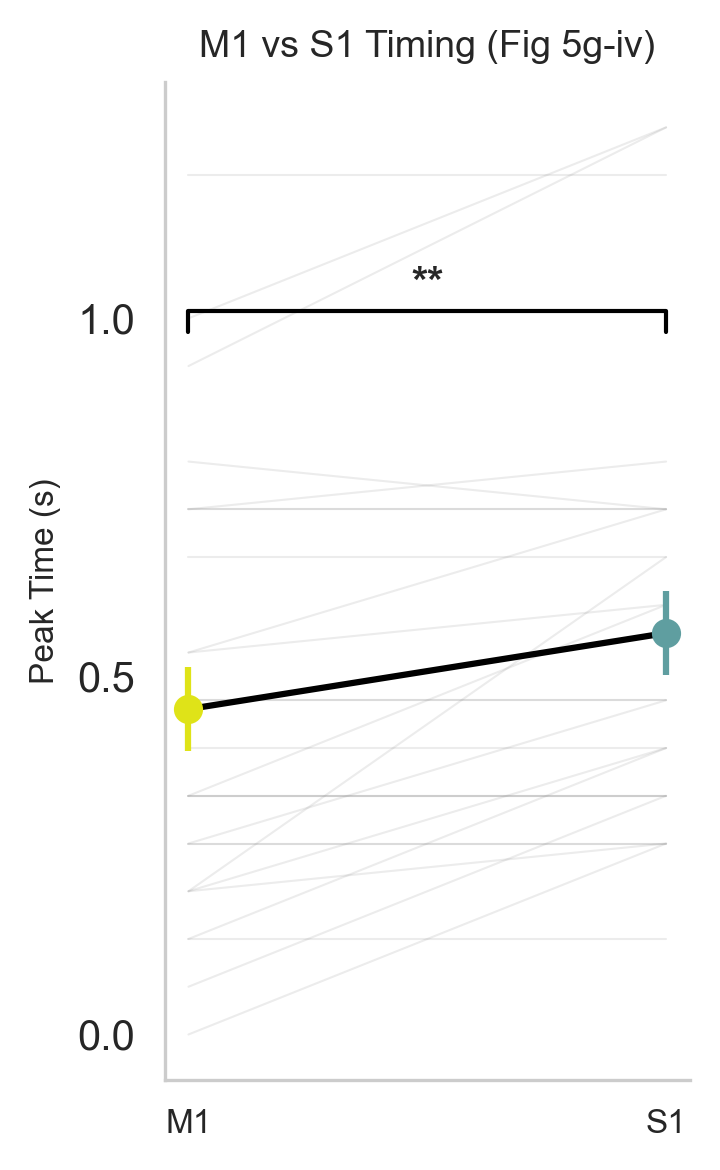

In [ ]:
t_stop = 45
t_start = 15
t_frame = np.linspace(-15, 30, 45).astype('int')
t_ax = np.divide(t_frame, 15)

# Fig 5g(iv): M1 vs S1 peak-timing statistics
M1_bouts = gcamp2plot['M1'][t_start:t_start + 20, :]
S1_bouts = gcamp2plot['S1'][t_start:t_start + 20, :]

m1_peak_idx = np.argmax(M1_bouts, axis=0)
s1_peak_idx = np.argmax(S1_bouts, axis=0)
m1_peak_times = t_ax[t_start + m1_peak_idx]
s1_peak_times = t_ax[t_start + s1_peak_idx]

fig, ax7 = plt.subplots(figsize=(2.5, 4), dpi=300)
plt.rcParams['svg.fonttype'] = 'none'

for m, s in zip(m1_peak_times, s1_peak_times):
    ax7.plot([0, 1], [m, s], color='gray', alpha=0.15, linewidth=0.5, zorder=1)

s1_mean, s1_sem = np.mean(s1_peak_times), stats.sem(s1_peak_times)
m1_mean, m1_sem = np.mean(m1_peak_times), stats.sem(m1_peak_times)
ax7.errorbar(0, m1_mean, yerr=m1_sem, color=viridis(0.95), marker='o', markersize=6, capsize=0, zorder=2)
ax7.errorbar(1, s1_mean, yerr=s1_sem, color='cadetblue', marker='o', markersize=6, capsize=0, zorder=2)
ax7.plot([0, 1], [m1_mean, s1_mean], color='black', linewidth=1.5, zorder=2)

ax7.set_xticks([0, 1])
ax7.set_xticklabels(['M1', 'S1'], fontsize=8)
ax7.set_ylabel('Peak Time (s)', fontsize=8)
ax7.set_title('M1 vs S1 Timing (Fig 5g-iv)', fontsize=9)
for axis in ['top', 'right']:
    ax7.spines[axis].set_linewidth(0)

stat, p_val = stats.wilcoxon(m1_peak_times, s1_peak_times)
num_bouts = len(m1_peak_times)
print(f"Fig 5g-iv (RHP, hindpaw, cm265) M1 vs S1 timing: statistic={stat:.4g}, "
      f"p-value = {p_val:.4e}, n = {num_bouts} bouts")

if p_val <= 0.0001:
    sig_star = '****'
elif p_val <= 0.001:
    sig_star = '***'
elif p_val <= 0.01:
    sig_star = '**'
elif p_val <= 0.05:
    sig_star = '*'
else:
    sig_star = 'ns'

y_max = np.max([s1_mean, m1_mean]) + 0.4
h_offset = 0.05
bracket_h = 0.02
ax7.plot([0, 0, 1, 1], [y_max + bracket_h, y_max + h_offset, y_max + h_offset, y_max + bracket_h],
         lw=1, c='black', zorder=3)
ax7.text(0.5, y_max + h_offset + 0.01, sig_star, ha='center', va='bottom', fontsize=10, fontweight='bold')
ax7.set_yticks([0, 0.5, 1])

plt.tight_layout()
plt.savefig('fig5g-iv-M1-vs-S1-timing.svg', format='svg', dpi=300)
